# TASK 4: DỰ ĐOÁN KHÁCH CÓ MUA LẠI TRONG 90 NGÀY HAY KHÔNG

**Bài toán:** với mỗi khách đã từng mua hàng, mô hình đoán xem khách đó **có mua lại trong 90 ngày tới hay không**.

- **Đáp án cần dự đoán:** cột `Mua_lai_90_ngay`, trong đó **1** là có mua lại và **0** là không mua lại.
- **Dữ liệu:** `data_khach_hang.csv` (1.000 khách, mỗi khách một dòng, đã chuẩn bị ở Stage 1).



## Bước 1. Nạp thư viện và đọc dữ liệu

In [1]:
# --- Thư viện xử lý dữ liệu và vẽ biểu đồ ---
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Thư viện học máy (scikit-learn) ---
from sklearn.model_selection import train_test_split    # chia dữ liệu thành train / test
from sklearn.preprocessing import StandardScaler        # đưa các cột về cùng thang đo
from sklearn.linear_model import LogisticRegression     # mô hình 1
from sklearn.tree import DecisionTreeClassifier         # mô hình 2
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_score, recall_score, f1_score)

import joblib   # dùng để lưu mô hình ở bước cuối

df = pd.read_csv('data_khach_hang.csv')
df.head()

,CustomerID,Frequency,MonetaryGBP,TotalUnits,AvgProductsPerInvoice,Country,Kenh_lien_he_mo_phong,RecencyDays,ObservedTenureDays,AvgOrderValueGBP,Chi_tieu_90_ngay_GBP,Mua_lai_90_ngay,RegionGroup
0,12354,1,1079.40,530,58.000000,Spain,Email,132,132,1079.400000,0.00,0,Other countries
1,12358,3,1774.04,622,17.333333,Austria,Phone,50,450,591.346667,0.00,0,Other countries
2,12363,2,552.00,408,11.500000,Unspecified,SMS,9,142,276.000000,0.00,0,Other countries
3,12365,2,641.38,174,11.000000,Cyprus,SMS,191,191,320.690000,0.00,0,Other countries
4,12370,5,3018.07,2053,29.600000,Cyprus,SMS,174,524,603.614000,739.28,1,Other countries


## Bước 2. Chọn dữ liệu đầu vào (X) và đáp án (y)

**X** gồm 7 cột mô tả hành vi mua hàng của khách **trước ngày 01/09/2011**:

| Cột | Ý nghĩa |
|---|---|
| `RecencyDays` | Số ngày từ lần mua gần nhất đến ngày 01/09/2011 |
| `Frequency` | Số hóa đơn đã mua |
| `MonetaryGBP` | Tổng tiền đã chi (bảng Anh) |
| `TotalUnits` | Tổng số sản phẩm đã mua |
| `AvgProductsPerInvoice` | Số mã sản phẩm khác nhau trung bình trên mỗi hóa đơn |
| `ObservedTenureDays` | Số ngày từ lần mua đầu tiên đến ngày 01/09/2011 |
| `AvgOrderValueGBP` | Giá trị trung bình mỗi hóa đơn (`MonetaryGBP` chia `Frequency`) |

**Không đưa vào X:**
- `Chi_tieu_90_ngay_GBP`: là số tiền khách chi *sau* ngày 01/09/2011. Nếu đưa vào thì mô hình "biết trước đáp án" (khách có chi tiêu lớn hơn 0 thì chắc chắn đã mua lại).
- `CustomerID` (chỉ là mã khách), `Kenh_lien_he_mo_phong` (dữ liệu mô phỏng), `Country` và `RegionGroup` .

In [2]:
# Các cột dùng để dự đoán
features = ['RecencyDays', 'Frequency', 'MonetaryGBP', 'TotalUnits',
            'AvgProductsPerInvoice', 'ObservedTenureDays', 'AvgOrderValueGBP']

X = df[features]               # dữ liệu đầu vào
y = df['Mua_lai_90_ngay']      # đáp án: 1 = mua lại, 0 = không mua lại

print('Số khách:', len(df))
print('Số cột đầu vào:', len(features))

Số khách: 1000
Số cột đầu vào: 7


## Bước 3. Kiểm tra số khách mua lại và không mua lại có chênh nhau nhiều không
Nếu một nhóm quá ít khách, mô hình dễ bỏ qua nhóm đó. Vì vậy cần đếm trước.

In [3]:
print('Số khách theo từng nhóm (0 = không mua lại, 1 = mua lại):')
print(y.value_counts())
print()
print('Tỷ lệ (%):')
print((y.value_counts(normalize=True) * 100).round(1))

Số khách theo từng nhóm (0 = không mua lại, 1 = mua lại):
Mua_lai_90_ngay
0    557
1    443
Name: count, dtype: int64

Tỷ lệ (%):
Mua_lai_90_ngay
0    55.7
1    44.3
Name: proportion, dtype: float64


**Kết quả:** 557 khách không mua lại (55,7%) và 443 khách mua lại (44,3%).

Hai nhóm chênh nhau **không nhiều**, nên không cần nhân bản hay xóa bớt dữ liệu. Ở bước huấn luyện, mình vẫn đặt `class_weight='balanced'` để mô hình coi trọng hai nhóm như nhau.

## Bước 4. Chia dữ liệu: 80% để học (train), 20% để kiểm tra (test)
- Mô hình chỉ được **học** trên tập train. Tập test là "bài kiểm tra" mô hình chưa từng thấy.
- `stratify=y` giúp tỷ lệ mua lại ở train và test giống nhau.
- `random_state=42` giúp mỗi lần chạy ra cùng một kết quả.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,        # 20% khách để kiểm tra
    stratify=y,           # giữ tỷ lệ mua lại giống nhau ở hai tập
    random_state=42)

print('Số khách để học (train):', len(X_train))
print('Số khách để kiểm tra (test):', len(X_test))

Số khách để học (train): 800
Số khách để kiểm tra (test): 200


## Bước 5. Đưa các cột về cùng thang đo (chỉ cần cho Logistic Regression)
Các cột có độ lớn rất khác nhau: `MonetaryGBP` có thể lên tới hàng nghìn, còn `Frequency` chỉ vài đơn vị. Logistic Regression cần các cột cùng thang đo, còn cây quyết định thì không cần.

Cách làm đúng là **học** cách chuẩn hóa chỉ từ tập train (`fit_transform`), rồi **áp dụng lại** cho tập test (`transform`). Làm vậy thì tập test không "lộ" thông tin cho mô hình.

In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # học cách chuẩn hóa từ train, rồi chuẩn hóa train
X_test_scaled = scaler.transform(X_test)         # chỉ chuẩn hóa test, không học lại

## Bước 6. Huấn luyện 2 mô hình
- **Logistic Regression:** tính ra xác suất khách sẽ mua lại từ các cột đầu vào.
- **Decision Tree (cây quyết định):** hỏi liên tiếp các câu dạng "nếu... thì...". Giới hạn cây **tối đa 3 tầng** (`max_depth=3`) để cây không học thuộc dữ liệu.

In [6]:
# Mô hình 1: Logistic Regression (học trên dữ liệu đã chuẩn hóa)
logistic = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
logistic.fit(X_train_scaled, y_train)

# Mô hình 2: Decision Tree, tối đa 3 tầng (học trên dữ liệu gốc)
tree = DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=42)
tree.fit(X_train, y_train)

print('Đã huấn luyện xong 2 mô hình.')

Đã huấn luyện xong 2 mô hình.


**Thử xem điều gì xảy ra nếu không giới hạn số tầng của cây:**

In [7]:
tree_khong_gioi_han = DecisionTreeClassifier(class_weight='balanced', random_state=42)
tree_khong_gioi_han.fit(X_train, y_train)

print('Cây không giới hạn - độ chính xác trên train:', round(tree_khong_gioi_han.score(X_train, y_train), 3))
print('Cây không giới hạn - độ chính xác trên test :', round(tree_khong_gioi_han.score(X_test, y_test), 3))

Cây không giới hạn - độ chính xác trên train: 1.0
Cây không giới hạn - độ chính xác trên test : 0.595


**Kết quả:** cây không giới hạn đúng 100% trên train nhưng chỉ khoảng 59,5% trên test. Nghĩa là cây đã **học thuộc** dữ liệu cũ chứ không học được quy luật. Vì vậy mô hình cây dùng ở các bước sau là cây giới hạn 3 tầng.

## Bước 7. Dự đoán trên tập test và in báo cáo
Cách đọc báo cáo (với nhóm **Mua lại**):
- **Precision:** trong số khách mô hình báo "sẽ mua lại", bao nhiêu phần trăm là đúng.
- **Recall:** trong số khách thật sự mua lại, mô hình tìm ra được bao nhiêu phần trăm.
- **F1:** điểm tổng hợp của Precision và Recall (càng cao càng tốt).
- **Accuracy:** tỷ lệ dự đoán đúng trên tất cả khách.

In [8]:
pred_logistic = logistic.predict(X_test_scaled)   # dự đoán của Logistic Regression
pred_tree = tree.predict(X_test)                  # dự đoán của Decision Tree

class_names = ['Không mua lại', 'Mua lại']

print('===== Logistic Regression =====')
print(classification_report(y_test, pred_logistic, target_names=class_names))

print('===== Decision Tree =====')
print(classification_report(y_test, pred_tree, target_names=class_names))

===== Logistic Regression =====
               precision    recall  f1-score   support

Không mua lại       0.78      0.78      0.78       111
      Mua lại       0.73      0.73      0.73        89

     accuracy                           0.76       200
    macro avg       0.76      0.76      0.76       200
 weighted avg       0.76      0.76      0.76       200

===== Decision Tree =====
               precision    recall  f1-score   support

Không mua lại       0.76      0.66      0.71       111
      Mua lại       0.63      0.74      0.68        89

     accuracy                           0.69       200
    macro avg       0.70      0.70      0.69       200
 weighted avg       0.70      0.69      0.70       200


## Bước 8. Confusion matrix (bảng đếm dự đoán đúng và sai)
Mỗi ô là số khách. **Hàng** là thực tế, **cột** là dự đoán.
- Đường chéo (trên trái và dưới phải) là các dự đoán **đúng**.
- Hai ô còn lại là các dự đoán **sai**.

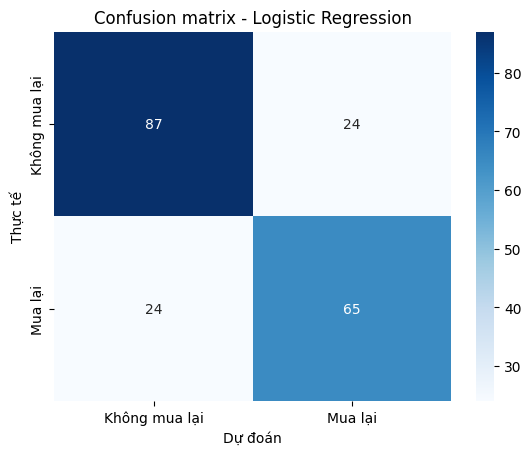

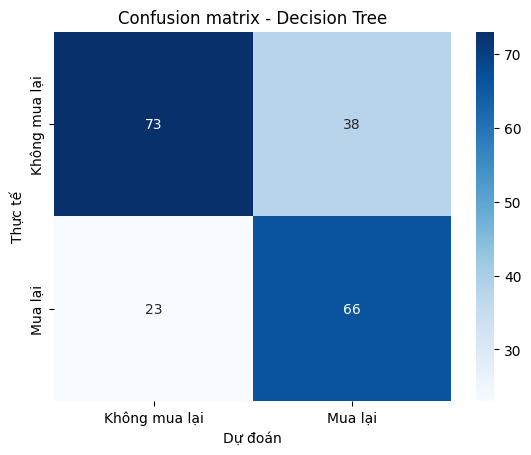

In [9]:
def plot_confusion(y_true, y_pred, title):
    matrix = confusion_matrix(y_true, y_pred)
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(title)
    plt.xlabel('Dự đoán')
    plt.ylabel('Thực tế')
    plt.show()

plot_confusion(y_test, pred_logistic, 'Confusion matrix - Logistic Regression')
plot_confusion(y_test, pred_tree, 'Confusion matrix - Decision Tree')

## Bước 9. So sánh hai mô hình

In [10]:
def get_scores(y_true, y_pred):
    return [accuracy_score(y_true, y_pred),
            precision_score(y_true, y_pred),    # tính cho nhóm Mua lại
            recall_score(y_true, y_pred),
            f1_score(y_true, y_pred)]

bang_so_sanh = pd.DataFrame(
    {'Logistic Regression': get_scores(y_test, pred_logistic),
     'Decision Tree': get_scores(y_test, pred_tree)},
    index=['Accuracy', 'Precision (mua lại)', 'Recall (mua lại)', 'F1 (mua lại)'])

bang_so_sanh.round(3)

,Logistic Regression,Decision Tree
Accuracy,0.76,0.695
Precision (mua lại),0.73,0.635
Recall (mua lại),0.73,0.742
F1 (mua lại),0.73,0.684


**Kết luận:** trong lần chia này, **Logistic Regression tốt hơn** vì cao hơn ở Accuracy, Precision và F1. Decision Tree chỉ nhỉnh hơn ở Recall: cây tìm ra nhiều khách mua lại hơn nhưng cũng báo nhầm nhiều hơn.



## Bước 10. Lưu mô hình để dùng cho giao diện (Task 5)
Giao diện cần cả `scaler` và `logistic`, vì Logistic Regression đã học trên dữ liệu được chuẩn hóa.

In [11]:
joblib.dump({'scaler': scaler,
             'logistic': logistic,
             'tree': tree,
             'features': features},
            'model_task4_don_gian.joblib')

print('Đã lưu file model_task4_don_gian.joblib')

Đã lưu file model_task4_don_gian.joblib
